# 03.1 · 因子是什么 · 反转因子 · 预处理

> 模块 3「因子研究」是整个量化选股的核心，也是面试问得最多的部分。
> 本节你将学会：**因子的本质、因子为什么能赚钱、手工实现第一个因子（20 日反转）、以及把原始因子处理成"干净可用"的标准流程**。
>
> 中性化、IC、分层回测在 03.2–03.5 深入。

## 一、什么是因子

**因子（Factor）= 每个时刻、对每只股票给出的一个数值（一个"打分"），用来预测它未来的收益。**

数学上，因子是一个关于「时间 t × 股票 i」的函数：

$$ f(t, i) \in \mathbb{R} $$

- 固定一个时刻 t，看所有股票，叫一个**截面（cross-section）**——因子研究主要在截面上做；
- 固定一只股票 i，看时间，叫一个**时间序列（time series）**。

**核心假设**：因子值与股票未来收益之间存在**稳定、可重复**的关系。比如"过去 20 天跌得多的股票，未来一段时间倾向于反弹"——如果这个规律长期成立，它就是一个有效因子。

> 因子 vs 指标：技术指标（如 MACD）也是数值，但只有当它被**严格检验**证明对未来收益有预测力时，才叫"因子"。

## 二、因子为什么能赚钱（收益来源）

一个因子能持续产生收益，通常来自三类原因，**面试时要能说清楚你研究的因子属于哪一类**：

1. **风险补偿（Risk Premium）**：你承担了某种系统性风险，市场因此给你回报。
   例：市值因子（小盘股风险大）、价值因子（低估值公司基本面更脆弱）。这类因子的收益是"应得的"。
2. **行为偏差（Behavioral Bias）**：投资者并非完全理性，会过度反应、反应不足、锚定、追涨杀跌。
   例：**短期反转**来自投资者对坏消息的过度反应，随后价格回归。
3. **微观结构（Market Microstructure）**：流动性、买卖价差、冲击成本。
   例：流动性差的股票需要给持有者更高补偿。

### 反转因子的逻辑

- **短期反转（Short-term Reversal）**：过去 1 个月内跌得最多的股票，往往是被恐慌性抛售、超跌，未来倾向于反弹。
- 行为金融学解释：投资者对信息**过度反应（overreaction）**，价格短期偏离基本面，随后均值回归。
- 注意它与**动量（Momentum）**相反：A 股 1 个月内多为反转，3–12 个月在不同市场动量/反转表现不同，需要实测。

## 三、准备数据：把后复权收盘价整理成宽表

从 Qlib 读回沪深300日频数据，把它整理成「日期 × 股票」的**宽表**（每行一个交易日，每列一只股票）——这是因子计算最方便的形式。

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
raw = D.features(codes, ['$close'], freq='day')
close = raw['$close'].unstack('instrument')   # 宽表：行=日期，列=股票
print('宽表形状（日期 × 股票）:', close.shape)
close.iloc[-3:, :4]

[14940:MainThread](2026-10-29 18:34:19,049) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[14940:MainThread](2026-10-29 18:34:20,550) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[14940:MainThread](2026-10-29 18:34:20,551) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


宽表形状（日期 × 股票）: (2139, 300)


instrument,SH600000,SH600009,SH600010,SH600011
datetime,,,,
2026-10-27,170.643295,76.636948,17.135311,39.973923
2026-10-28,171.164612,76.508362,17.051313,41.313831
2026-10-29,173.597412,76.476212,16.799324,42.318760


## 四、实现 20 日反转因子

**定义**：20 日反转因子 = 负的「过去 20 个交易日累计收益率」：

$$ \text{REV20}(t,i) = -\left(\frac{P_t}{P_{t-20}} - 1\right) $$

- 加负号是为了让因子方向统一为"**因子值越大、未来预期收益越高**"：跌得越多（累计收益越负），反转因子值越大；
- 这是因子研究的通用约定：**因子方向统一为正向预测**。

In [2]:
ret20 = close.pct_change(20)   # 过去20日累计收益
rev20 = -ret20               # 反转因子
print('因子宽表形状:', rev20.shape)
print('\n最新一个交易日（2026-10-29）的截面分布：')
print(rev20.iloc[-1].describe())

因子宽表形状: (2139, 300)

最新一个交易日（2026-10-29）的截面分布：
count    300.000000
mean       0.063550
std        0.137646
min       -0.278244
25%       -0.030644
50%        0.038585
75%        0.134986
max        0.512228
Name: 2026-10-29 00:00:00, dtype: float64


把最新截面的因子分布画出来。可以看到：
- 有一个明显的范围（约 -0.28 ~ 0.51）；
- 不同股票的因子值差异很大，但**量纲、极值、分布形态**还没处理——这正是下一步要做的。

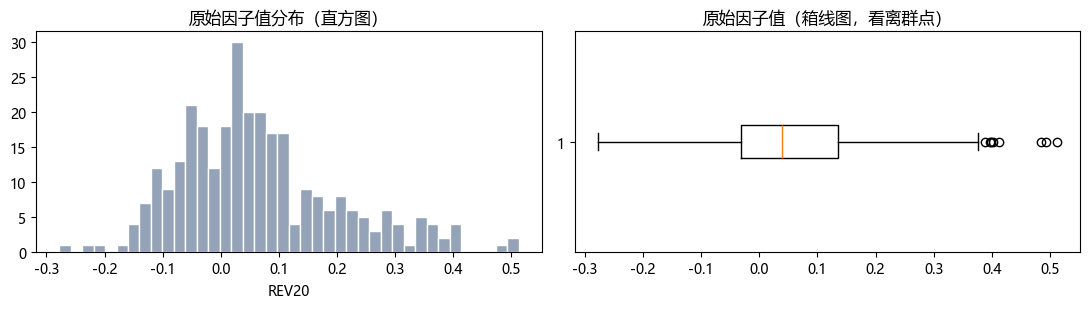

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
s = rev20.iloc[-1].dropna()
axes[0].hist(s, bins=40, color='#94a3b8', edgecolor='white')
axes[0].set_title('原始因子值分布（直方图）'); axes[0].set_xlabel('REV20')
axes[1].boxplot(s, vert=False); axes[1].set_title('原始因子值（箱线图，看离群点）')
plt.tight_layout(); plt.show()

## 五、因子预处理：为什么必须做

原始因子直接拿来用会有几个问题：

1. **极端值（outlier）**：个别股票因停牌、重组、异常波动，因子值极端大/小，会主导结果；
2. **量纲不统一**：不同因子的数值范围不同（反转因子是 ±0.5，市值因子是几百亿），无法直接比较/合成；
3. **缺失值**：新股历史不足、停牌，会产生 NaN。

标准处理顺序：**去极值 → 标准化 → 缺失值处理**。下面逐个讲透。

> 注意：所有处理都必须在**每个截面（每个交易日）内部**独立进行，不能用未来信息（这是防止前视偏差的关键）。

### 5.1 去极值（Winsorize）

把超出合理范围的值"截断"到边界，而不是删除（删除会改变股票集合）。三种常见方法：

**① 3σ 法（均值 ± n 倍标准差）**：简单，但均值和标准差本身会被极值带偏，不够稳健。

**② MAD 法（中位数 + n 倍 MAD）**：用中位数和「中位数绝对偏差」，**对极值稳健，最常用**。

**③ 分位数缩尾**：直接把低于 1%、高于 99% 分位的值截断，直观、稳健。

In [4]:
def winsorize_3sigma(x, n=3):
    x = pd.Series(x).astype(float)
    mu, sd = x.mean(), x.std()
    return x.clip(mu - n*sd, mu + n*sd)

def winsorize_mad(x, n=3):
    x = pd.Series(x).astype(float)
    med = x.median()
    mad = (x - med).abs().median()
    bound = n * 1.4826 * mad          # 1.4826 使 MAD 与标准差在正态下一致
    return x.clip(med - bound, med + bound)

def winsorize_quantile(x, lower=0.01, upper=0.99):
    x = pd.Series(x).astype(float)
    lo, hi = x.quantile(lower), x.quantile(upper)
    return x.clip(lo, hi)

s = rev20.iloc[-1].dropna()
for name, f in [('3σ', winsorize_3sigma), ('MAD', winsorize_mad),
                ('分位数', winsorize_quantile)]:
    out = f(s)
    print(f'{name:4s} 截断后范围: [{out.min():.3f}, {out.max():.3f}]')

3σ   截断后范围: [-0.278, 0.476]
MAD  截断后范围: [-0.278, 0.383]
分位数  截断后范围: [-0.173, 0.414]


对比三种方法处理后的分布（看箱线图离群点是否被压回）：

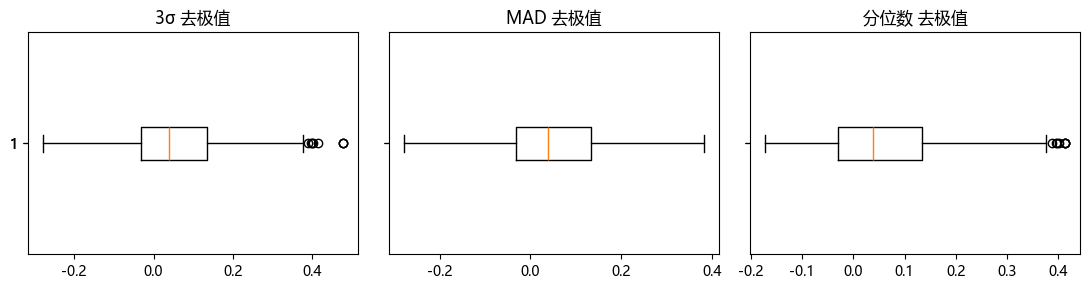

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, (name, f) in zip(axes, [('3σ', winsorize_3sigma), ('MAD', winsorize_mad),
                                 ('分位数', winsorize_quantile)]):
    ax.boxplot(f(s), vert=False); ax.set_title(f'{name} 去极值')
plt.tight_layout(); plt.show()

### 5.2 标准化（Standardization）

去极值后，需要把因子变成统一量纲，便于跨因子比较、合成，也让模型更稳定。

**① Z-score 标准化**：变成均值 0、标准差 1：

$$ z = \frac{x - \mu}{\sigma} $$

**② Rank 标准化**：先在截面排名，再映射到 [-1, 1]（或正态分位）。**对分布形态完全不敏感，A 股实战最稳健、最常用**，尤其适合非线性、厚尾的因子。

Z-score   : mean=0.000 std=1.000 range=[-2.48, 3.26]
Rank标准化 : mean=0.003 std=0.578 range=[-0.99, 1.00]


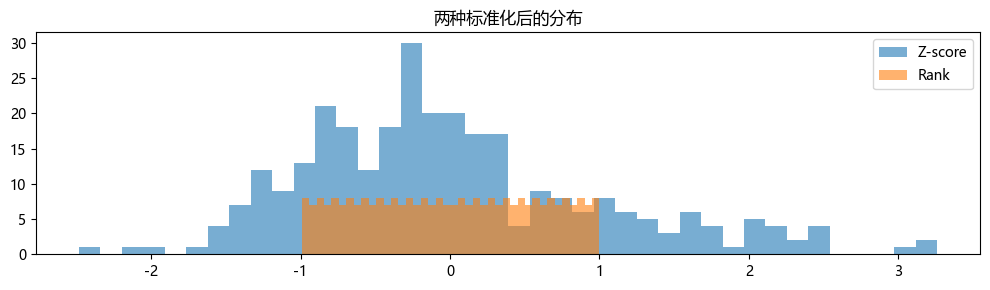

In [6]:
def zscore(x):
    x = pd.Series(x).astype(float)
    return (x - x.mean()) / x.std()

def rank_norm(x):
    x = pd.Series(x).astype(float)
    return x.rank(pct=True) * 2 - 1     # 映射到 [-1, 1]

z = zscore(s); r = rank_norm(s)
print('Z-score   : mean=%.3f std=%.3f range=[%.2f, %.2f]' % (z.mean(), z.std(), z.min(), z.max()))
print('Rank标准化 : mean=%.3f std=%.3f range=[%.2f, %.2f]' % (r.mean(), r.std(), r.min(), r.max()))

plt.figure(figsize=(10, 3))
plt.hist(z, bins=40, alpha=.6, label='Z-score')
plt.hist(r, bins=40, alpha=.6, label='Rank')
plt.legend(); plt.title('两种标准化后的分布'); plt.tight_layout(); plt.show()

### 5.3 缺失值处理

因子缺失的原因：**新股历史不足**（前 20 个交易日算不出 REV20）、**停牌**。常见处理：

- **截面填充为中性值**：标准化后缺失填 0（即"不看好也不看空"），最常用；
- **直接剔除**：该股票当日不参与；
- 注意：不能用未来数据填充，也不应在因子计算时引入前视。

In [7]:
# 看一个截面有多少缺失
s_raw = rev20.iloc[-1]
print('截面总股票数:', len(s_raw), ' 缺失:', s_raw.isna().sum())
# 标准化后缺失填 0（中性）
r = rank_norm(s_raw).fillna(0)
print('处理后缺失:', r.isna().sum(), ' 中性值附近(0)个数:', (r==0).sum())

截面总股票数: 300  缺失: 0
处理后缺失: 0  中性值附近(0)个数: 1


### 5.4 把整套流程封装成一个函数

下面把"去极值 → Rank 标准化 → 缺失填 0"封装，对**每个交易日的截面**统一处理，得到干净的因子面板。后续所有因子都走这个函数。

In [8]:
def process_factor(factor, winsor='mad', standardize='rank'):
    def one_cross(x):
        x = x.astype(float)
        if winsor == 'mad':
            x = winsorize_mad(x)
        elif winsor == 'quantile':
            x = winsorize_quantile(x)
        if standardize == 'rank':
            x = rank_norm(x)
        else:
            x = zscore(x)
        return x.fillna(0.0)
    return factor.apply(one_cross, axis=1)   # 逐截面处理

rev20_clean = process_factor(rev20)
print('处理后形状:', rev20_clean.shape)
print('最新截面分布：'); print(rev20_clean.iloc[-1].describe())
print('总缺失:', rev20_clean.isna().sum().sum())

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

处理后形状: (2139, 300)
最新截面分布：
count    300.000000
mean       0.003333
std        0.578306
min       -0.993333
25%       -0.495000
50%        0.003333
75%        0.501667
max        0.976667
Name: 2026-10-29 00:00:00, dtype: float64
总缺失: 0


## 六、小结与面试要点

**本节你应该掌握：**
- 因子是「时间 × 股票」的打分，核心是与未来收益有稳定关系；研究在**截面**上做。
- 因子收益三来源：**风险补偿、行为偏差、微观结构**；反转因子主要来自过度反应后的均值回归。
- 因子方向统一为"值越大、预期收益越高"。
- 预处理三步：**去极值（MAD 最稳健）→ 标准化（Rank 最稳健）→ 缺失填中性值**，且必须在每个截面内独立进行（防前视）。

**面试高频问题：**
- 为什么要去极值？MAD 相比 3σ 好在哪？（答：MAD 用中位数，不被极值带偏，更稳健）
- Z-score 和 Rank 标准化的区别？A 股为什么常用 Rank？（答：Rank 对分布不敏感，抗极值、抗厚尾）
- 预处理为什么要按截面、不能全样本一起做？（答：避免未来信息泄漏）

## 动手练习
1. 把窗口改成 5 日、60 日，看看因子分布有何不同；
2. 把 `process_factor` 里的标准化改成 zscore，对比结果；
3. 思考：反转因子在什么市场环境（牛市/熊市/震荡）可能失效？

---
下一节 **03.2 因子中性化**：为什么要剔除行业和市值的影响，如何用回归做中性化。